In [ ]:
!pip install numpy matplotlib


In [ ]:
d_E = r * dphi_E              # deslocamento da roda esquerda
d_D = r * dphi_D              # deslocamento da roda direita
ds     = (d_D + d_E) / 2      # deslocamento do centro do robô
dtheta = (d_D - d_E) / L      # variação de orientação

x     = x + ds * cos(theta + dtheta/2)
y     = y + ds * sin(theta + dtheta/2)
theta = theta + dtheta


In [1]:
# lab2_utils.py
import math
import numpy as np

def normaliza_angulo(a):
    """Leva o ângulo para o intervalo (-pi, pi]."""
    return math.atan2(math.sin(a), math.cos(a))

def atualiza_odometria(x, y, theta, dphi_e, dphi_d, r, L):
    """Integra um passo de odometria. Retorna a nova pose (x, y, theta)."""
    d_e = r * dphi_e
    d_d = r * dphi_d
    ds = (d_d + d_e) / 2
    dtheta = (d_d - d_e) / L
    x += ds * math.cos(theta + dtheta / 2)
    y += ds * math.sin(theta + dtheta / 2)
    theta = normaliza_angulo(theta + dtheta)
    return x, y, theta

def scan_para_mundo(ranges, angle_min, angle_increment, pose,
                    range_min=0.12, range_max=3.5, passo=1):
    """Converte um scan em pontos (N x 2) no referencial global.
    - descarte leituras inválidas (inf, nan, fora de [range_min, range_max])
    - use apenas 1 a cada 'passo' feixes
    - pose = (x, y, theta) do robô no mundo
    """
    indices = np.arange(len(ranges))[::passo]
    distancias = np.asarray(ranges, dtype=float)[::passo]
    validos = (np.isfinite(distancias)
               & (distancias >= range_min)
               & (distancias <= range_max))
    distancias = distancias[validos]
    angulos = angle_min + indices[validos] * angle_increment
    x, y, theta = pose
    return np.column_stack((x + distancias * np.cos(theta + angulos),
                            y + distancias * np.sin(theta + angulos)))


In [2]:
from lab2_utils import *

# Valores FICTÍCIOS, usados só nos testes (os reais serão medidos em sala)
R, L = 0.05, 0.20

# Teste 1: ambas as rodas giram 1 rad -> robô anda em linha reta R*1
x, y, t = atualiza_odometria(0, 0, 0, 1.0, 1.0, R, L)
assert abs(x - R) < 1e-6 and abs(y) < 1e-6 and abs(t) < 1e-6

# Teste 2: rodas em sentidos opostos -> gira sem sair do lugar
x, y, t = atualiza_odometria(0, 0, 0, -1.0, 1.0, R, L)
assert abs(x) < 1e-6 and abs(y) < 1e-6
assert abs(t - 2 * R / L) < 1e-6

# Teste 3: robô em (1, 0) virado para +y; feixe frontal de 1 m
# deve atingir o ponto (1, 1) no mundo
pts = scan_para_mundo([1.0], 0.0, 0.01, (1.0, 0.0, math.pi/2))
assert pts.shape == (1, 2)
assert abs(pts[0, 0] - 1.0) < 1e-6 and abs(pts[0, 1] - 1.0) < 1e-6

# Teste 4: leituras inválidas devem ser descartadas
pts = scan_para_mundo([float('inf'), 0.0, 1.0], 0.0, 0.1, (0, 0, 0))
assert pts.shape == (1, 2)

print('Todos os testes passaram!')


Todos os testes passaram!


In [3]:
import time, math, threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from lab2_utils import *

ROBOT_IP = '192.168.0.135'         # <-- IP do seu robô
NS = ''                            # prefixo dos tópicos, ex: '/tb03' (só se o professor indicar)

# Parâmetros geométricos: MEDIDOS por vocês na seção 2.2.1 (em metros)
R_RODA = 0.0   # <-- raio da roda medido
L_EIXO = 0.0   # <-- distância entre as rodas medida
# assert R_RODA > 0 and L_EIXO > 0, 'Preencha R_RODA e L_EIXO com os valores medidos!'

client = roslibpy.Ros(host=ROBOT_IP, port=9090)
client.run()
print('Conectado:', client.is_connected)

Conectado: True


In [4]:
import time, math, threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from lab2_utils import *

ROBOT_IP = '192.168.0.135'         # <-- IP do seu robô
NS = ''                            # prefixo dos tópicos, ex: '/tb03' (só se o professor indicar)

# Parâmetros geométricos: MEDIDOS por vocês na seção 2.2.1 (em metros)
R_RODA = 0.03   # <-- raio da roda medido
L_EIXO = 0.28  # <-- distância entre as rodas medida
assert R_RODA > 0 and L_EIXO > 0, 'Preencha R_RODA e L_EIXO com os valores medidos!'

client = roslibpy.Ros(host=ROBOT_IP, port=9090)
client.run()
print('Conectado:', client.is_connected)

# --- estado compartilhado entre os callbacks ---
phi_prev   = [None]          # última leitura das rodas (esq, dir)
pose_prop = [0.0, 0.0, 0.0] # sua odometria (x, y, theta)
traj_prop = []               # histórico da sua odometria
traj_odom = []               # histórico de /odom: (x, y)
ultimo_scan = [None]

def cb_joint(msg):
    i_e = msg['name'].index('wheel_left_joint')
    i_d = msg['name'].index('wheel_right_joint')
    phi_e, phi_d = msg['position'][i_e], msg['position'][i_d]
    if phi_prev[0] is not None:
        dphi_e = phi_e - phi_prev[0][0]
        dphi_d = phi_d - phi_prev[0][1]
        x, y, th = pose_prop
        pose_prop[:] = atualiza_odometria(x, y, th, dphi_e, dphi_d, R_RODA, L_EIXO)
        traj_prop.append(tuple(pose_prop))
    phi_prev[0] = (phi_e, phi_d)

def cb_odom(msg):
    p = msg['pose']['pose']['position']
    traj_odom.append((p['x'], p['y']))            # usaremos apenas a posição

def cb_scan(msg):
    ultimo_scan[0] = msg

t_joint = roslibpy.Topic(client, NS + '/joint_states', 'sensor_msgs/JointState')
t_odom = roslibpy.Topic(client, NS + '/odom', 'nav_msgs/Odometry')
t_scan = roslibpy.Topic(client, NS + '/scan', 'sensor_msgs/LaserScan')
t_joint.subscribe(cb_joint)
t_odom.subscribe(cb_odom)
t_scan.subscribe(cb_scan)

time.sleep(2)
print('joint:', len(traj_prop), '| odom:', len(traj_odom), '| scan:', ultimo_scan[0] is not None)


Conectado: True
joint: 38 | odom: 39 | scan: True


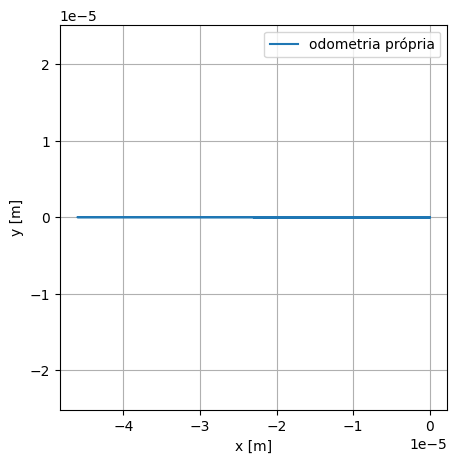

In [26]:
cmd_vel = roslibpy.Topic(client, NS + '/cmd_vel', 'geometry_msgs/Twist')

def move(v, w, duracao, freq=10):
    """Publica (v, w) a 'freq' Hz durante 'duracao' segundos e para."""
    msg = roslibpy.Message({'linear': {'x': v, 'y': 0.0, 'z': 0.0},
                              'angular': {'x': 0.0, 'y': 0.0, 'z': w}})
    t0 = time.time()
    while time.time() - t0 < duracao:
        cmd_vel.publish(msg)
        time.sleep(1.0 / freq)
    cmd_vel.publish(roslibpy.Message({'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
                                       'angular': {'x': 0.0, 'y': 0.0, 'z': 0.0}}))
    time.sleep(0.3)

def trajetoria():
    """Trajetória do grupo: EDITE livremente (v em m/s, w em rad/s, duração em s)."""
    move(-0.21, 0.0, 10)    # reta
    move(0.0, 0.4, 3.35)    # giro no lugar
    move(-0.21, 0.0, 10)    # reta

    # move(-0.1, 0.3, 5)    # curva
    # move(-0.1, 0.0, 3)    # reta

# Marca o início do experimento
traj_prop.clear(); traj_odom.clear(); pose_prop[:] = [0.0, 0.0, 0.0]
trajetoria()

P = np.array(traj_prop)
plt.figure(figsize=(5, 5))
plt.plot(P[:, 0], P[:, 1], label='odometria própria')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x [m]'); plt.ylabel('y [m]'); plt.show()


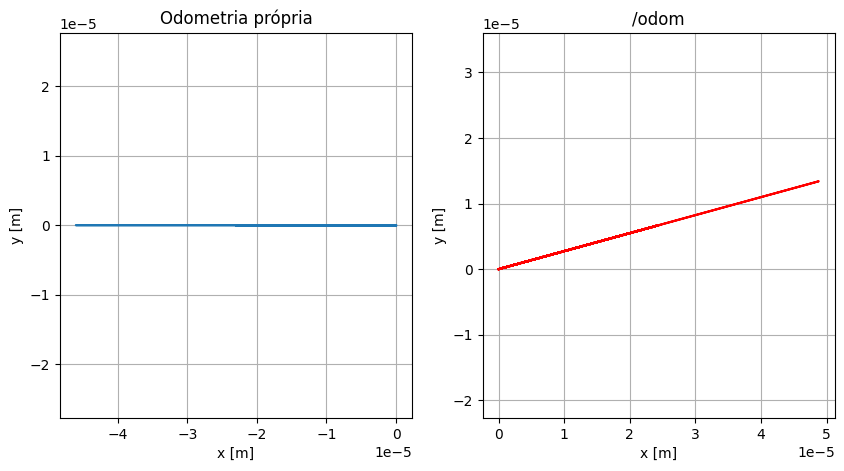

In [27]:
O = np.array(traj_odom)
O = O - O[0]          # começa na origem

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(P[:, 0], P[:, 1]); ax[0].set_title('Odometria própria')
ax[1].plot(O[:, 0], O[:, 1], 'r'); ax[1].set_title('/odom')
for a in ax:
    a.axis('equal'); a.grid(True); a.set_xlabel('x [m]'); a.set_ylabel('y [m]')
plt.show()


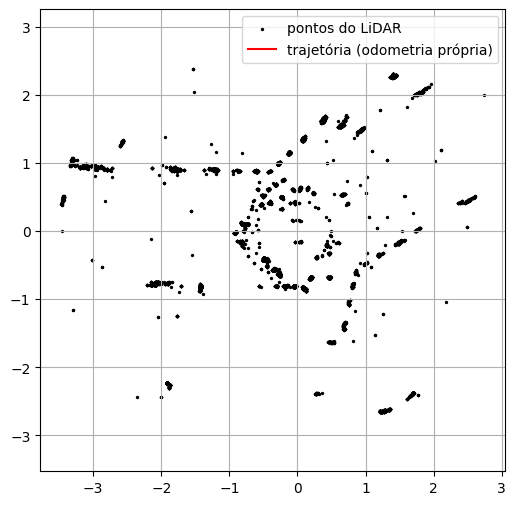

In [ ]:
def trajetoria():
    """Trajetória do grupo: EDITE livremente (v em m/s, w em rad/s, duração em s)."""
    move(-0.21, 0.0, 10)    # reta
    move(0.0, 0.4, 3.35)    # giro no lugar
    move(-0.21, 0.0, 10)    # reta

    # move(-0.1, 0.3, 5)    # curva
    # move(-0.1, 0.0, 3)    # reta


def mapear(passo=6, freq=20):
    """Roda a trajetória em uma thread e acumula o mapa enquanto o robô anda."""
    nuvem = []
    th = threading.Thread(target=trajetoria)
    th.start()
    while th.is_alive():
        s = ultimo_scan[0]
        if s is not None:
            pts = scan_para_mundo(s['ranges'], s['angle_min'], s['angle_increment'],
                                  tuple(pose_prop), passo=passo)
            nuvem.append(pts)
        time.sleep(1.0 / freq)
    return np.vstack(nuvem)

traj_prop.clear(); pose_prop[:] = [0.0, 0.0, 0.0]
mapa = mapear()

P = np.array(traj_prop)
plt.figure(figsize=(6, 6))
plt.scatter(mapa[:, 0], mapa[:, 1], s=2, c='k', label='pontos do LiDAR')
plt.plot(P[:, 0], P[:, 1], 'r-', label='trajetória (odometria própria)')
plt.axis('equal'); plt.grid(True); plt.legend(); plt.show(); plt.savefig()


## Experimento: mapa e telemetria em tempo real

As dez células originais foram preservadas. A nova célula mostra o mapa do LiDAR e
um painel de telemetria durante o movimento.

1. Execute a célula original completa de conexão e callbacks, com `R_RODA`, `L_EIXO`
   e as inscrições em `/joint_states`, `/odom` e `/scan`. Confira IP e medidas.
2. Execute diretamente a célula abaixo. Ela já realiza o percurso. As células antigas
   de `trajetoria()` e `mapear()` ficam como referência e iniciam outro percurso se executadas.
3. Ao terminar, use a célula original de desligamento, logo depois desta.
   Se já desligou a conexão, execute a célula completa de conexão novamente.

Foi mantida a sequência do último texto enviado: dois trechos de 5 s com
`v=-0.25 m/s`, separados pela etapa de duração zero e pelas pausas de 0.3 s do código.
`passo=3`, `freq_plot=5` e `freq_cmd=10` também foram mantidos. Uma velocidade
linear negativa representa o comando para andar para trás.

O painel mostra comando enviado, velocidades linear e angular de `/odom`,
velocidades calculadas pelos encoders, pose própria, percurso estimado do centro,
etapa atual, contagem de mensagens e idade desde a recepção dos três sensores.
Os scans recebidos e os scans incorporados ao mapa têm contagens distintas:
o mapa incorpora o scan mais recente disponível a cada consulta.

Os estados distinguem movimento indicado por `/odom`, rodas girando sem confirmação
em `/odom`, repouso, comando sem movimento detectado e ausência de dados recentes.
As leituras vencidas não confirmam movimento. `timeout_dados=1.0` limita a idade das
leituras, e `espera_resposta=1.0` é a tolerância antes de indicar comando sem resposta.
Os limiares de movimento são 0.01 m/s e 0.03 rad/s, editáveis no código.

A telemetria indica resposta pelos encoders e pela odometria; patinagem pode produzir
leituras sem deslocamento físico correspondente. A idade mede recepção na máquina,
sem sincronizar relógios ou comprovar avanço dos timestamps dos sensores.
A mensagem [`nav_msgs/Odometry`](https://github.com/ros/common_msgs/blob/noetic-devel/nav_msgs/msg/Odometry.msg)
contém estimativas de posição e velocidade.

Use **Interromper/Interrupt** para cancelar o percurso e solicitar velocidade zero.
Os dados ficam em `mapa_tempo_real`, `P_tempo_real`, `fig_tempo_real` e
`telemetria_tempo_real` (lista dos snapshots, inclusive se houver interrupção).

A telemetria observa os tópicos já inscritos com `client.on` e remove apenas seus
próprios observadores com `client.off(nome, callback)`, preservando os callbacks
originais, conforme a [API do roslibpy](https://roslibpy.readthedocs.io/en/latest/reference/index.html#roslibpy.Ros.off).


In [ ]:
# NOVA CÉLULA: execute depois da conexão e das inscrições nos sensores.
# Mapa e telemetria ao vivo: comando enviado, /odom e resposta dos encoders.
import time
import threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from IPython.display import display
from lab2_utils import scan_para_mundo

# Sequência do texto enviado: (v [m/s], w [rad/s], duração [s]).
ETAPAS_TEMPO_REAL = [
    (-0.25, 0.0, 5.0),
    (0.0, 0.0, 0.0),
    (-0.25, 0.0, 5.0),
]


def mapear_tempo_real(passo=6, freq_plot=5, freq_cmd=10,
                     timeout_dados=1.0, espera_resposta=1.0, historico=None):
    """Mostra mapa, comando e movimento indicado pelos sensores em tempo real.

    A telemetria usa os tópicos já inscritos pela célula de conexão.
    Odometria/encoders indicam resposta do robô; não são referência externa
    para comprovar deslocamento físico em caso de patinagem.
    """
    if 'client' not in globals() or not client.is_connected:
        raise RuntimeError('Execute novamente a célula de conexão com os sensores.')
    necessarios = ('NS', 'ultimo_scan', 'traj_prop', 'traj_odom', 'pose_prop',
                  'phi_prev', 'R_RODA', 'L_EIXO')
    if any(nome not in globals() for nome in necessarios):
        raise RuntimeError('Execute a célula completa de conexão e callbacks dos sensores.')
    if R_RODA <= 0 or L_EIXO <= 0:
        raise ValueError('Preencha R_RODA e L_EIXO com as medidas do robô.')
    if ultimo_scan[0] is None or phi_prev[0] is None:
        raise RuntimeError('Sem leituras: confira as inscrições em /joint_states e /scan.')
    if passo < 1 or int(passo) != passo or freq_plot <= 0 or freq_cmd <= 0:
        raise ValueError('Use passo inteiro >= 1 e frequências positivas.')
    if timeout_dados <= 0 or espera_resposta < 0:
        raise ValueError('Use timeout_dados > 0 e espera_resposta >= 0.')
    passo = int(passo)

    # Um publicador independente; as funções antigas continuam disponíveis.
    comando = roslibpy.Topic(client, NS + '/cmd_vel', 'geometry_msgs/Twist')
    parar = threading.Event()
    erros = []
    nuvem = []
    ultimo_processado = ultimo_scan[0]  # ignora o scan anterior ao experimento
    numero_scans = 0
    inicio = time.monotonic()
    trava = threading.Lock()
    # None significa que ainda não recebemos uma medida válida nesta execução.
    tele = dict(v_cmd=0.0, w_cmd=0.0, n_cmd=0, t_cmd=None,
                inicio_comando=None, etapa=0, distancia_rodas=0.0,
                v_odom=None, w_odom=None, v_rodas=None, w_rodas=None,
                n_joint=0, n_odom=0, n_scan=0,
                t_joint=None, t_odom=None, t_scan=None)
    encoder_anterior = None
    registrados = []

    def valor_valido(valor):
        try:
            valor = float(valor)
            return valor if np.isfinite(valor) else None
        except (TypeError, ValueError):
            return None

    def monitor_odom(msg):
        twist = msg.get('twist', {}).get('twist', {})
        with trava:
            tele.update(t_odom=time.monotonic(), n_odom=tele['n_odom'] + 1,
                        v_odom=valor_valido(twist.get('linear', {}).get('x')),
                        w_odom=valor_valido(twist.get('angular', {}).get('z')))

    def monitor_joint(msg):
        nonlocal encoder_anterior
        agora = time.monotonic()
        stamp = msg.get('header', {}).get('stamp', {})
        seg, nano = valor_valido(stamp.get('secs')), valor_valido(stamp.get('nsecs', 0))
        t_ros = seg + nano * 1e-9 if seg is not None and nano is not None else None
        if t_ros is not None and t_ros <= 0:
            t_ros = None
        try:
            e = valor_valido(msg['position'][msg['name'].index('wheel_left_joint')])
            d = valor_valido(msg['position'][msg['name'].index('wheel_right_joint')])
        except (KeyError, ValueError, IndexError, TypeError):
            e = d = None
        with trava:
            tele.update(t_joint=agora, n_joint=tele['n_joint'] + 1,
                        v_rodas=None, w_rodas=None)
            if e is None or d is None:
                encoder_anterior = None
                return
            if encoder_anterior is not None:
                ant_receb, ant_ros, ant_e, ant_d = encoder_anterior
                # Prefere o intervalo do sensor ao intervalo de chegada pela rede.
                dt = t_ros - ant_ros if t_ros is not None and ant_ros is not None else agora - ant_receb
                if 1e-6 < dt <= timeout_dados:
                    de, dd = R_RODA * (e - ant_e), R_RODA * (d - ant_d)
                    ds = (de + dd) / 2
                    tele.update(v_rodas=ds / dt, w_rodas=(dd - de) / (L_EIXO * dt))
                    tele['distancia_rodas'] += abs(ds)
            encoder_anterior = (agora, t_ros, e, d)

    def monitor_scan(msg):
        with trava:
            tele.update(t_scan=time.monotonic(), n_scan=tele['n_scan'] + 1)

    # Observa os eventos existentes; não cria outra inscrição nos mesmos tópicos.
    observadores = [(NS + '/odom', monitor_odom),
                    (NS + '/joint_states', monitor_joint),
                    (NS + '/scan', monitor_scan)]

    def publicar(v=0.0, w=0.0):
        comando.publish(roslibpy.Message({
            'linear': {'x': v, 'y': 0.0, 'z': 0.0},
            'angular': {'x': 0.0, 'y': 0.0, 'z': w},
        }))
        agora = time.monotonic()
        with trava:
            if v or w:
                if not (tele['v_cmd'] or tele['w_cmd']):
                    tele['inicio_comando'] = agora
            else:
                tele['inicio_comando'] = None
            tele.update(v_cmd=v, w_cmd=w, n_cmd=tele['n_cmd'] + 1, t_cmd=agora)

    def executar_movimentos():
        # Só esta thread envia movimento; o desenho fica na thread principal.
        try:
            for indice, (v, w, duracao) in enumerate(ETAPAS_TEMPO_REAL, start=1):
                with trava:
                    tele['etapa'] = indice
                fim = time.monotonic() + duracao
                while not parar.is_set():
                    restante = fim - time.monotonic()
                    if restante <= 0:
                        break
                    publicar(v, w)
                    if parar.wait(min(1.0 / freq_cmd, restante)):
                        return
                publicar()
                if parar.wait(0.3):  # mesma pausa entre movimentos do código original
                    return
        except Exception as erro:
            erros.append(erro)
        finally:
            try:
                publicar()
            except Exception as erro:
                erros.append(erro)

    def coletar_scan():
        nonlocal ultimo_processado, numero_scans
        s = ultimo_scan[0]
        if s is not None and s is not ultimo_processado:
            ultimo_processado = s
            pontos = scan_para_mundo(
                s['ranges'], s['angle_min'], s['angle_increment'],
                tuple(pose_prop),
                range_min=s.get('range_min', 0.12),
                range_max=s.get('range_max', 3.5),
                passo=passo,
            )
            numero_scans += 1
            if pontos.size:
                nuvem.append(pontos)

    # Cria os elementos gráficos uma vez e atualiza os seus dados no loop.
    with plt.ioff():
        fig, (ax, painel) = plt.subplots(1, 2, figsize=(13, 7),
                                       gridspec_kw={'width_ratios': [1.4, 1]})
    fig.subplots_adjust(left=0.06, right=0.98, bottom=0.09, top=0.91, wspace=0.16)
    pontos_lidar = ax.scatter([], [], s=2, c='k', label='pontos do LiDAR')
    linha, = ax.plot([], [], 'r-', label='trajetória (odometria própria)')
    robo, = ax.plot([], [], 'bo', markersize=6, label='posição atual')
    ax.set(xlabel='x [m]', ylabel='y [m]', title='Preparando mapa ao vivo')
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.grid(True)
    ax.legend(loc='upper right')
    painel.axis('off')
    painel.set_title('Telemetria ao vivo', loc='left', fontweight='bold')
    texto_estado = painel.text(0, 0.95, 'Aguardando sensores', va='top',
                               fontsize=11, fontweight='bold', transform=painel.transAxes)
    texto_tele = painel.text(0, 0.85, '', va='top', fontsize=10,
                            fontfamily='monospace', linespacing=1.35,
                            transform=painel.transAxes)
    painel.text(0, 0.01, 'Resposta indicada por odometria/encoders.\n'
                'A idade mostra o tempo desde a recepção.',
                fontsize=9, color='dimgray', transform=painel.transAxes)
    saida = display(fig, display_id=True)

    def atualizar_telemetria():
        with trava:
            dados = tele.copy()
        agora = time.monotonic()
        dados['tempo_s'] = agora - inicio
        dados['conectado'] = bool(client.is_connected)
        for sensor in ('joint', 'odom', 'scan'):
            t = dados['t_' + sensor]
            dados['idade_' + sensor] = None if t is None else agora - t

        def recente(sensor):
            idade = dados['idade_' + sensor]
            return idade is not None and idade <= timeout_dados

        def valido(fonte, sensor):
            return recente(sensor) and all(dados[chave + '_' + fonte] is not None
                                           for chave in ('v', 'w'))

        odom_valido = valido('odom', 'odom')
        rodas_validas = valido('rodas', 'joint')
        # Limiares ajustáveis para rejeitar pequenos ruídos em repouso.
        move_odom = odom_valido and (abs(dados['v_odom']) > 0.01 or abs(dados['w_odom']) > 0.03)
        move_rodas = rodas_validas and (abs(dados['v_rodas']) > 0.01 or abs(dados['w_rodas']) > 0.03)
        com_comando = bool(dados['v_cmd'] or dados['w_cmd'])
        if not dados['conectado']:
            status, cor = 'DESCONECTADO', 'firebrick'
        elif not (odom_valido or rodas_validas):
            status, cor = 'SEM TELEMETRIA RECENTE', 'darkorange'
        elif (move_odom or move_rodas) and not com_comando:
            status, cor = 'MOVIMENTO COM COMANDO ZERO', 'darkorange'
        elif move_odom:
            status, cor = 'MOVIMENTO INDICADO POR /odom', 'forestgreen'
        elif move_rodas:
            status, cor = 'RODAS GIRANDO; CONFIRA /odom', 'darkorange'
        elif com_comando and agora - dados['inicio_comando'] >= espera_resposta:
            status, cor = 'COMANDO SEM MOVIMENTO DETECTADO', 'firebrick'
        elif com_comando:
            status, cor = 'AGUARDANDO RESPOSTA', 'darkorange'
        else:
            status, cor = 'PARADO SEGUNDO OS SENSORES', 'dimgray'
        dados['status'] = status
        dados['pose'] = tuple(pose_prop)
        if historico is not None:
            historico.append(dados)

        def velocidade(fonte):
            sensor = 'joint' if fonte == 'rodas' else 'odom'
            if fonte != 'cmd' and not recente(sensor):
                return '  sem dados recentes'
            v, w = dados['v_' + fonte], dados['w_' + fonte]
            v = '--' if v is None else f'{v:+.3f}'
            w = '--' if w is None else f'{w:+.3f}'
            return f'  v={v} m/s  w={w} rad/s'

        def recepcao(sensor):
            idade = dados['idade_' + sensor]
            texto = 'sem dados' if idade is None else f'{idade:.2f} s'
            if idade is not None and not recente(sensor):
                texto += ' ATRASADO'
            return f"  {sensor:5s}: {dados['n_' + sensor]:5d} msgs | {texto}"

        x, y, theta = dados['pose']
        texto_estado.set_text(status)
        texto_estado.set_color(cor)
        texto_tele.set_text(
            f"Tempo: {dados['tempo_s']:.1f} s | etapa {dados['etapa']}/{len(ETAPAS_TEMPO_REAL)}\n\n"
            'Comando enviado (/cmd_vel):\n' + velocidade('cmd') + '\n\n'
            '/odom medido:\n' + velocidade('odom') + '\n\n'
            'Estimativa pelos encoders:\n' + velocidade('rodas') + '\n\n'
            f'Pose própria: x={x:+.3f} m y={y:+.3f} m\n'
            f'Orientação: {np.degrees(theta):+.1f} graus\n'
            f"Percurso do centro: {dados['distancia_rodas']:.3f} m\n\n"
            'Recepção (mensagens | idade):\n' + '\n'.join(recepcao(s) for s in ('joint', 'odom', 'scan'))
            + f"\nPublicações de comando: {dados['n_cmd']}"
        )

    def atualizar_grafico(estado):
        mapa_atual = np.vstack(nuvem) if nuvem else np.empty((0, 2))
        traj_atual = np.asarray(traj_prop[:], dtype=float).reshape(-1, 3)
        x, y, _ = tuple(pose_prop)
        pontos_lidar.set_offsets(mapa_atual)
        linha.set_data(traj_atual[:, 0], traj_atual[:, 1])
        robo.set_data([x], [y])
        # Inclui os pontos do scatter nos limites, mesmo sem trajetória ainda.
        todos = np.vstack((mapa_atual, traj_atual[:, :2], [[0, 0], [x, y]]))
        minimo, maximo = todos.min(axis=0), todos.max(axis=0)
        centro = (minimo + maximo) / 2
        meia_largura = max(maximo - minimo) / 2 + 0.5
        ax.set_xlim(centro[0] - meia_largura, centro[0] + meia_largura)
        ax.set_ylim(centro[1] - meia_largura, centro[1] + meia_largura)
        ax.set_title(f'{estado} | {numero_scans} scans | {len(mapa_atual)} pontos')
        atualizar_telemetria()
        saida.update(fig)  # substitui a figura na mesma saída do notebook
        return mapa_atual, traj_atual

    # Novo experimento: a origem da odometria própria volta a (0, 0, 0).
    traj_prop.clear()
    traj_odom.clear()
    pose_prop[:] = [0.0, 0.0, 0.0]
    phi_prev[0] = None
    trabalhador = threading.Thread(target=executar_movimentos, daemon=True,
                                   name='movimento_tempo_real')
    estado = 'Concluído'
    proximo_plot = 0.0
    try:
        for nome, callback in observadores:
            client.on(nome, callback)
            registrados.append((nome, callback))
        trabalhador.start()
        while trabalhador.is_alive():
            coletar_scan()
            agora = time.monotonic()
            if agora >= proximo_plot:
                atualizar_grafico('Mapeando ao vivo')
                proximo_plot = time.monotonic() + 1.0 / freq_plot
            time.sleep(0.01)
    except KeyboardInterrupt:
        estado = 'Interrompido'
    except Exception:
        estado = 'Erro'
        raise
    finally:
        # Interromper a célula também cancela os próximos movimentos.
        parar.set()
        try:
            if trabalhador.ident is not None:
                trabalhador.join()
        finally:
            try:
                publicar()  # envia zero após a thread parar
                coletar_scan()
                mapa_final, traj_final = atualizar_grafico('Erro' if erros else estado)
            finally:
                # Remove só os nossos observadores, mantendo os callbacks antigos.
                try:
                    for nome, callback in registrados:
                        try:
                            client.off(nome, callback)
                        except Exception as erro:
                            erros.append(erro)
                finally:
                    plt.close(fig)

    if erros:
        raise RuntimeError('Falha durante o movimento; parada solicitada.') from erros[0]
    print(f'{estado}: {numero_scans} scans processados, {len(mapa_final)} pontos.')
    return mapa_final, traj_final, fig


# Edite freq_plot para alterar a taxa desejada de atualização do gráfico.
telemetria_tempo_real = []  # snapshots do painel, inclusive se interromper a célula
mapa_tempo_real, P_tempo_real, fig_tempo_real = mapear_tempo_real(
    passo=3, freq_plot=5, freq_cmd=10, historico=telemetria_tempo_real,
)
# Para salvar depois: fig_tempo_real.savefig('mapa_tempo_real.png', dpi=150)


In [34]:
move(0.0, 0.0, 0.2)
t_joint.unsubscribe(); t_odom.unsubscribe(); t_scan.unsubscribe()
client.terminate()


AttributeError: 'TwistedEventLoopManager' object has no attribute '_thread'